# Your code or screenshots of your code

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm

In [3]:
ev_charging_data = pd.read_csv('ev_battery_charging_data.csv')  
print(ev_charging_data.head()) 

     SOC (%)  Voltage (V)  Current (A)  Battery Temp (°C)  Ambient Temp (°C)  \
0  43.708611     3.629593    33.553512          33.454060          26.439918   
1  95.564288     3.879331    32.228092          35.933628          31.108647   
2  75.879455     4.111062    91.562912          25.009358          30.203219   
3  63.879264     4.012557    32.459158          32.497482          18.077998   
4  24.041678     4.064593    34.475475          31.434920          17.984989   

   Charging Duration (min)  Degradation Rate (%) Charging Mode  \
0                59.363552              8.805096          Fast   
1                67.343566             12.186860          Fast   
2               105.454739             13.832336          Slow   
3                54.000439              9.318874          Fast   
4               106.964968             11.687577          Fast   

   Efficiency (%) Battery Type  Charging Cycles EV Model  \
0       98.238981       Li-ion              112  Model B   
1 

In [5]:
print("Column Headers:", ev_charging_data.columns.tolist())

Column Headers: ['SOC (%)', 'Voltage (V)', 'Current (A)', 'Battery Temp (°C)', 'Ambient Temp (°C)', 'Charging Duration (min)', 'Degradation Rate (%)', 'Charging Mode', 'Efficiency (%)', 'Battery Type', 'Charging Cycles', 'EV Model', 'Optimal Charging Duration Class']


In [7]:
# Transformations: lowercase, replace spaces w/ underscores, trim whitespace, remove special symbols/characters

ev_charging_data.columns = [col.lower().replace(" ", "_") for col in ev_charging_data.columns]  
ev_charging_data.columns = [col.strip() for col in ev_charging_data.columns]  
ev_charging_data.columns = [col.replace("%", "").replace("(", "").replace(")", "").replace("°", "") for col in ev_charging_data.columns]

print("Transformed Headers:", ev_charging_data.columns.tolist())

Transformed Headers: ['soc_', 'voltage_v', 'current_a', 'battery_temp_c', 'ambient_temp_c', 'charging_duration_min', 'degradation_rate_', 'charging_mode', 'efficiency_', 'battery_type', 'charging_cycles', 'ev_model', 'optimal_charging_duration_class']


## SOC

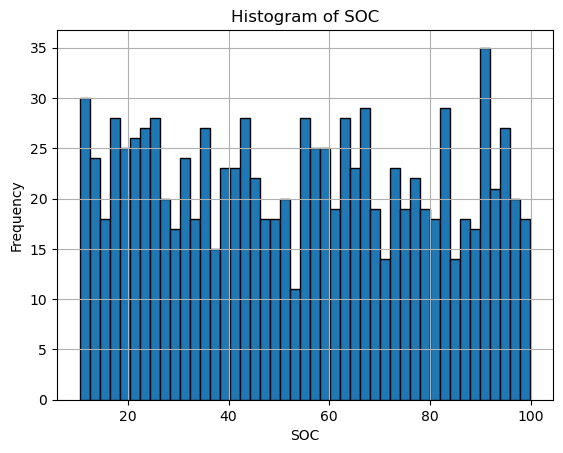

In [9]:
ev_charging_data['soc_'].hist(bins=45, edgecolor='black')

plt.xlabel('SOC')
plt.ylabel('Frequency')
plt.title('Histogram of SOC')

plt.show()

In [11]:
mean_soc = ev_charging_data.soc_.mean()
var_soc = ev_charging_data.soc_.var()
std_soc = ev_charging_data.soc_.std()
mode_soc = ev_charging_data.soc_.mode()

print(f"SOC Mean: {mean_soc:.2f}")
print(f"SOC Variance: {var_soc:.2f}")
print(f"SOC Standard Deviation: {std_soc:.2f}")
print(f"SOC Mode: {mode_soc}")

SOC Mean: 54.12
SOC Variance: 691.29
SOC Standard Deviation: 26.29
SOC Mode: 0      10.416882
1      10.455543
2      10.496991
3      10.625692
4      10.827735
         ...    
995    99.145463
996    99.366832
997    99.697315
998    99.718683
999    99.974591
Name: soc_, Length: 1000, dtype: float64


## Batt Temp

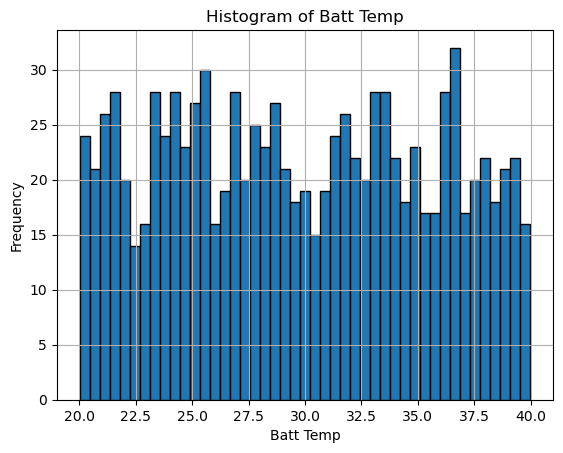

In [13]:
ev_charging_data['battery_temp_c'].hist(bins=45, edgecolor='black')

plt.xlabel('Batt Temp')
plt.ylabel('Frequency')
plt.title('Histogram of Batt Temp')

plt.show()

In [15]:
mean_batt_temp = ev_charging_data.battery_temp_c.mean()
var_batt_temp = ev_charging_data.battery_temp_c.var()
std_batt_temp = ev_charging_data.battery_temp_c.std()
mode_batt_temp = ev_charging_data.battery_temp_c.mode()

print(f"Batt Temp Mean: {mean_batt_temp:.2f}")
print(f"Batt Temp Variance: {var_batt_temp:.2f}")
print(f"Batt Temp Standard Deviation: {std_batt_temp:.2f}")
print(f"Batt Temp Mode: {mode_batt_temp}")

Batt Temp Mean: 29.81
Batt Temp Variance: 32.83
Batt Temp Standard Deviation: 5.73
Batt Temp Mode: 0      20.013068
1      20.039843
2      20.106270
3      20.127581
4      20.137559
         ...    
995    39.943647
996    39.944758
997    39.952566
998    39.977852
999    39.991154
Name: battery_temp_c, Length: 1000, dtype: float64


## Amb Temp

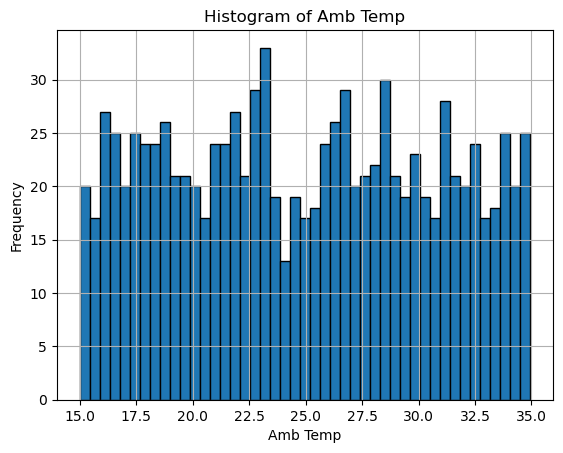

In [17]:
ev_charging_data['ambient_temp_c'].hist(bins=45, edgecolor='black')

plt.xlabel('Amb Temp')
plt.ylabel('Frequency')
plt.title('Histogram of Amb Temp')

plt.show()

In [19]:
mean_amb_temp = ev_charging_data.ambient_temp_c.mean()
var_amb_temp = ev_charging_data.ambient_temp_c.var()
std_amb_temp = ev_charging_data.ambient_temp_c.std()
mode_amb_temp = ev_charging_data.ambient_temp_c.mode()

print(f"Amb Temp Mean: {mean_amb_temp:.2f}")
print(f"Amb Temp Variance: {var_amb_temp:.2f}")
print(f"Amb Temp Standard Deviation: {std_amb_temp:.2f}")
print(f"Amb Temp Mode: {mode_amb_temp}")

Amb Temp Mean: 24.88
Amb Temp Variance: 32.90
Amb Temp Standard Deviation: 5.74
Amb Temp Mode: 0      15.000614
1      15.004541
2      15.011959
3      15.018868
4      15.022242
         ...    
995    34.911378
996    34.914689
997    34.930526
998    34.938988
999    34.954988
Name: ambient_temp_c, Length: 1000, dtype: float64


## Charge Duration

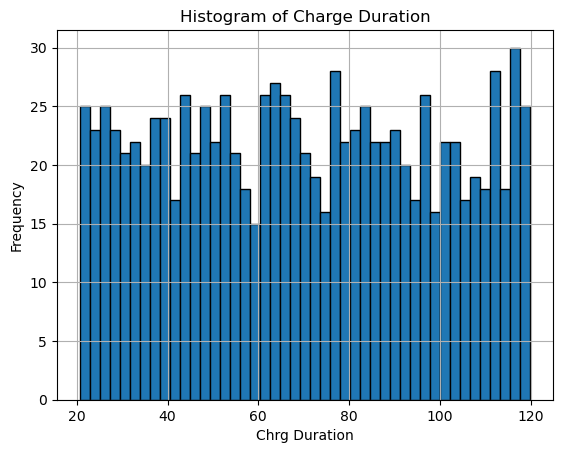

In [21]:
ev_charging_data['charging_duration_min'].hist(bins=45, edgecolor='black')

plt.xlabel('Chrg Duration')
plt.ylabel('Frequency')
plt.title('Histogram of Charge Duration')

plt.show()

In [23]:
mean_charge_dur = ev_charging_data.charging_duration_min.mean()
var_charge_dur = ev_charging_data.charging_duration_min.var()
std_charge_dur = ev_charging_data.charging_duration_min.std()
mode_charge_dur = ev_charging_data.charging_duration_min.mode()

print(f"Charge Duration Mean: {mean_charge_dur:.2f}")
print(f"Charge Duration Variance: {var_charge_dur:.2f}")
print(f"Charge Duration Standard Deviation: {std_charge_dur:.2f}")
print(f"Charge Duration Mode: {mode_charge_dur}")

Charge Duration Mean: 69.85
Charge Duration Variance: 836.34
Charge Duration Standard Deviation: 28.92
Charge Duration Mode: 0       20.618382
1       20.709181
2       20.735304
3       20.746314
4       20.861900
          ...    
995    119.564518
996    119.622449
997    119.767226
998    119.879294
999    119.935030
Name: charging_duration_min, Length: 1000, dtype: float64


## Degradation Rate

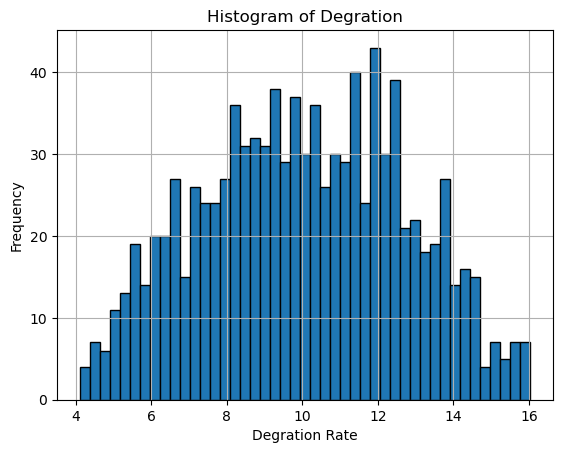

In [25]:
ev_charging_data['degradation_rate_'].hist(bins=45, edgecolor='black')

plt.xlabel('Degration Rate')
plt.ylabel('Frequency')
plt.title('Histogram of Degration')

plt.show()

In [27]:
mean_deg_rate = ev_charging_data.degradation_rate_.mean()
var_deg_rate = ev_charging_data.degradation_rate_.var()
std_deg_rate = ev_charging_data.degradation_rate_.std()
mode_deg_rate = ev_charging_data.degradation_rate_.mode()

print(f"Degradation Rate Mean: {mean_deg_rate:.2f}")
print(f"Degradation Rate Variance: {var_deg_rate:.2f}")
print(f"Degradation Rate Standard Deviation: {std_deg_rate:.2f}")
print(f"Degradation Rate Mode: {mode_deg_rate}")

Degradation Rate Mean: 10.02
Degradation Rate Variance: 7.27
Degradation Rate Standard Deviation: 2.70
Degradation Rate Mode: 0       4.102433
1       4.126044
2       4.259881
3       4.312585
4       4.418449
         ...    
995    15.861537
996    15.973104
997    16.006314
998    16.013058
999    16.042788
Name: degradation_rate_, Length: 1000, dtype: float64


## Charging Cycle

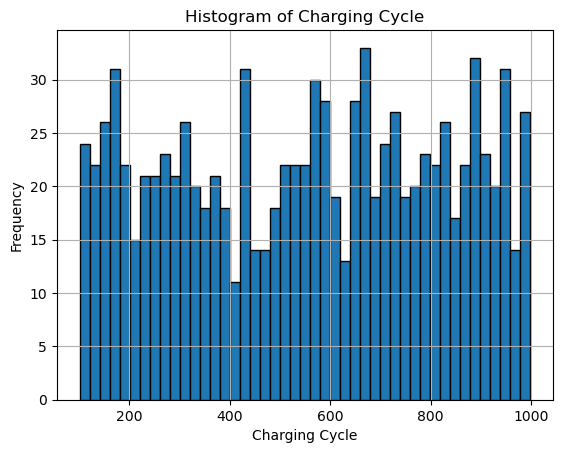

In [29]:
ev_charging_data['charging_cycles'].hist(bins=45, edgecolor='black')

plt.xlabel('Charging Cycle')
plt.ylabel('Frequency')
plt.title('Histogram of Charging Cycle')

plt.show()

In [31]:
mean_chrg_cycle = ev_charging_data.charging_cycles.mean()
var_chrg_cycle = ev_charging_data.charging_cycles.var()
std_chrg_cycle = ev_charging_data.charging_cycles.std()
mode_chrg_cycle = ev_charging_data.charging_cycles.mode()

print(f"Charging Cycle Mean: {mean_chrg_cycle:.2f}")
print(f"Charging Cycle Variance: {var_chrg_cycle:.2f}")
print(f"Charging Cycle Standard Deviation: {std_chrg_cycle:.2f}")
print(f"Charging Cycle Mode: {mode_chrg_cycle}")

Charging Cycle Mean: 556.56
Charging Cycle Variance: 69570.95
Charging Cycle Standard Deviation: 263.76
Charging Cycle Mode: 0    516
Name: charging_cycles, dtype: int64


## PMF

In [33]:
# Select two EV models for comparison
model_a_cycles = ev_charging_data[ev_charging_data["ev_model"] == "Model A"]["charging_cycles"]
model_b_cycles = ev_charging_data[ev_charging_data["ev_model"] == "Model B"]["charging_cycles"]

In [35]:
# Compute PMFs
pmf_a = model_a_cycles.value_counts(normalize=True).sort_index()
pmf_b = model_b_cycles.value_counts(normalize=True).sort_index()

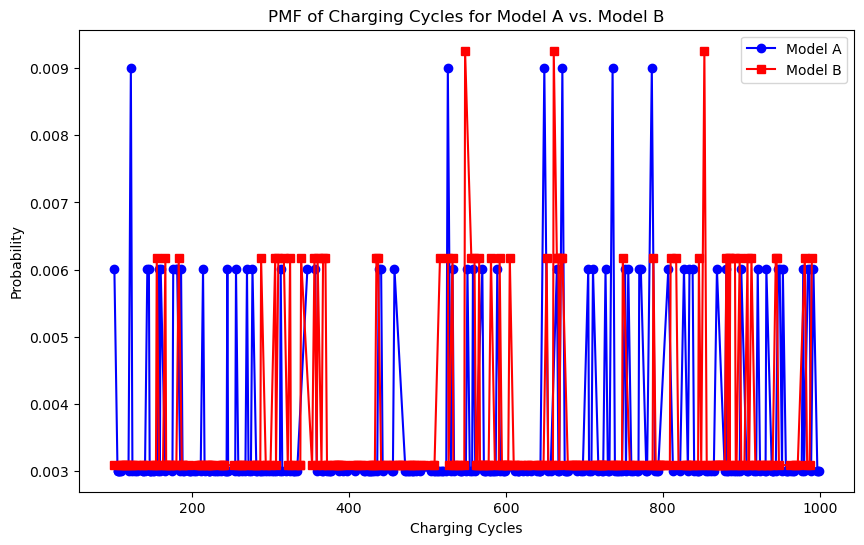

In [37]:
plt.figure(figsize=(10, 6))
plt.plot(pmf_a.index, pmf_a.values, marker='o', linestyle='-', label='Model A', color='blue')
plt.plot(pmf_b.index, pmf_b.values, marker='s', linestyle='-', label='Model B', color='red')

plt.xlabel("Charging Cycles")
plt.ylabel("Probability")
plt.title("PMF of Charging Cycles for Model A vs. Model B")
plt.legend()

plt.show()

## CDF

In [39]:
# Select two EV models for comparison (Model A vs. Model B)
model_a_duration = ev_charging_data[ev_charging_data["ev_model"] == "Model A"]["charging_duration_min"].sort_values()
model_b_duration = ev_charging_data[ev_charging_data["ev_model"] == "Model B"]["charging_duration_min"].sort_values()

In [41]:
# Compute CDF values
cdf_a = np.arange(1, len(model_a_duration) + 1) / len(model_a_duration)
cdf_b = np.arange(1, len(model_b_duration) + 1) / len(model_b_duration)

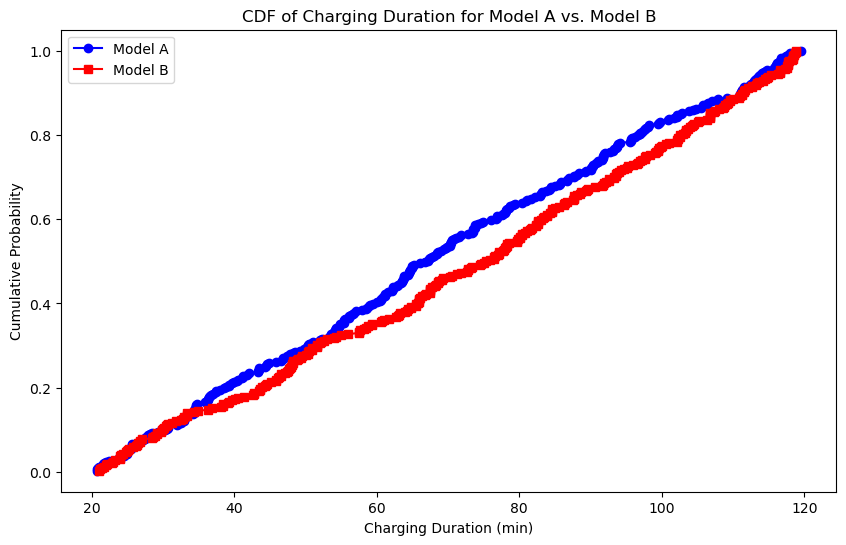

In [43]:
plt.figure(figsize=(10, 6))
plt.plot(model_a_duration, cdf_a, marker='o', linestyle='-', label='Model A', color='blue')
plt.plot(model_b_duration, cdf_b, marker='s', linestyle='-', label='Model B', color='red')

plt.xlabel("Charging Duration (min)")
plt.ylabel("Cumulative Probability")
plt.title("CDF of Charging Duration for Model A vs. Model B")
plt.legend()

plt.show()

## Analytical Distribution

In [45]:
# Select charging duration data (excluding NaN values)
charging_duration = ev_charging_data["charging_duration_min"].dropna()

# Fit a normal distribution (estimate mean and std dev)
mu, sigma = stats.norm.fit(charging_duration)

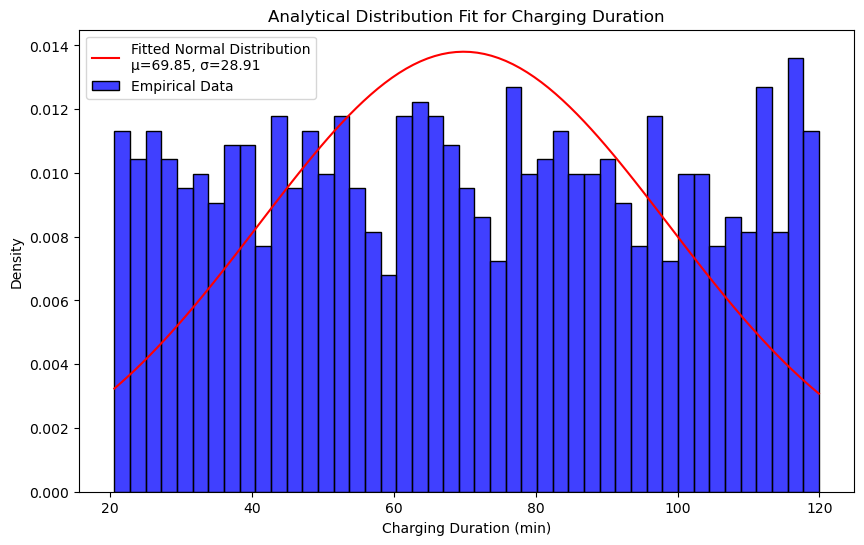

In [47]:
# Generate fitted distribution values
x = np.linspace(charging_duration.min(), charging_duration.max(), 100)
pdf = stats.norm.pdf(x, mu, sigma)  # Probability Density Function (PDF)

# Plot histogram of actual data
plt.figure(figsize=(10, 6))
sns.histplot(charging_duration, bins=45, kde=False, stat="density", color="blue", label="Empirical Data")

# Plot fitted normal distribution
plt.plot(x, pdf, color="red", label=f"Fitted Normal Distribution\nμ={mu:.2f}, σ={sigma:.2f}")

plt.xlabel("Charging Duration (min)")
plt.ylabel("Density")
plt.title("Analytical Distribution Fit for Charging Duration")
plt.legend()

plt.show()

## 2 Scatter Plots comparing 2 variables

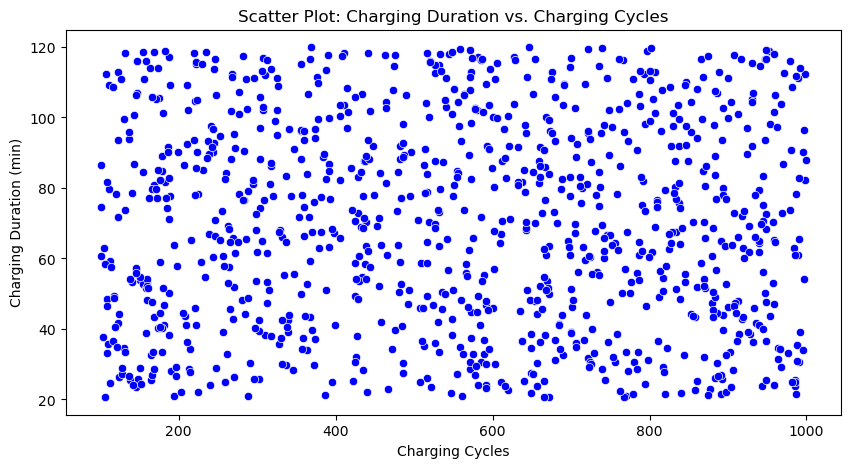

In [49]:
# Scatter Plot 1: Charging Cycles vs Charging Duration
plt.figure(figsize=(10, 5))
sns.scatterplot(x=ev_charging_data["charging_cycles"], y=ev_charging_data["charging_duration_min"], color="blue")

plt.xlabel("Charging Cycles")
plt.ylabel("Charging Duration (min)")
plt.title("Scatter Plot: Charging Duration vs. Charging Cycles")

plt.show()

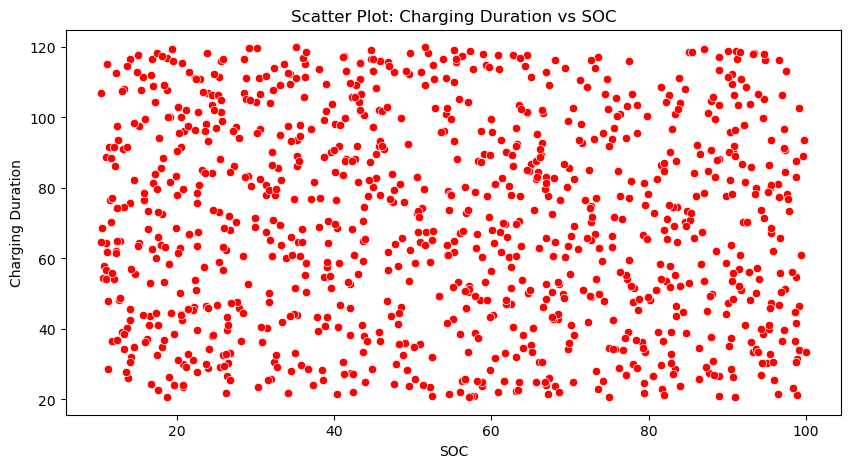

In [51]:
# Scatter Plot 2: SOC vs. Charging Duration
plt.figure(figsize=(10, 5))
sns.scatterplot(x=ev_charging_data["soc_"], y=ev_charging_data["charging_duration_min"], color="red")

plt.xlabel("SOC")
plt.ylabel("Charging Duration")
plt.title("Scatter Plot: Charging Duration vs SOC")

plt.show()

In [53]:
# Compute Pearson Correlation
corr_cycles, _ = stats.pearsonr(ev_charging_data["charging_cycles"], ev_charging_data["charging_duration_min"])
corr_soc, _ = stats.pearsonr(ev_charging_data["soc_"], ev_charging_data["charging_duration_min"])

print(f"Pearson Correlation (Charging Duration vs Charging Cycles): {corr_cycles:.2f}")
print(f"Pearson Correlation (Charging Duration vs SOC): {corr_soc:.2f}")

Pearson Correlation (Charging Duration vs Charging Cycles): -0.01
Pearson Correlation (Charging Duration vs SOC): -0.06


## Hypothesis Test

In [55]:
# Separate charging durations based on charging mode
fast_charging = ev_charging_data[ev_charging_data["charging_mode"] == "Fast"]["charging_duration_min"]
slow_charging = ev_charging_data[ev_charging_data["charging_mode"] == "Slow"]["charging_duration_min"]

# Check normality using the Shapiro-Wilk test
shapiro_fast = stats.shapiro(fast_charging)
shapiro_slow = stats.shapiro(slow_charging)
print("Shapiro-Wilk Test for Fast Charging:", shapiro_fast)
print("Shapiro-Wilk Test for Slow Charging:", shapiro_slow)

# Perform Mann-Whitney U test (non-parametric alternative to t-test)
mann_whitney_result = stats.mannwhitneyu(fast_charging, slow_charging, alternative="two-sided")
print("Mann-Whitney U Test Result:", mann_whitney_result)

Shapiro-Wilk Test for Fast Charging: ShapiroResult(statistic=0.9613616733923821, pvalue=1.7799658070056005e-07)
Shapiro-Wilk Test for Slow Charging: ShapiroResult(statistic=0.9495564883791464, pvalue=2.0883805080680235e-09)
Mann-Whitney U Test Result: MannwhitneyuResult(statistic=52557.0, pvalue=0.45420951561271117)


## Regression Analysis

In [57]:
# Define dependent and independent variables
explanatory = ev_charging_data["current_a"]  
dependent = ev_charging_data["charging_duration_min"]  

# Add a constant term for the intercept
explanatory = sm.add_constant(explanatory)

# Perform linear regression
model = sm.OLS(dependent, explanatory).fit()

# Print summary of regression results
print(model.summary())

                              OLS Regression Results                             
Dep. Variable:     charging_duration_min   R-squared:                       0.000
Model:                               OLS   Adj. R-squared:                 -0.001
Method:                    Least Squares   F-statistic:                    0.4136
Date:                   Sat, 15 Mar 2025   Prob (F-statistic):              0.520
Time:                           14:00:03   Log-Likelihood:                -4782.7
No. Observations:                   1000   AIC:                             9569.
Df Residuals:                        998   BIC:                             9579.
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         71.0888 